# Phase 2: Spatial statistics

**Input:** `data/processed_v2/yield_labels_v2.gpkg` (from Phase 1B). The 3 impossible yields are removed, so 1,202 fields remain.
**Output:** `data/processed_v2/yield_spatial_v2.gpkg` (fields plus LISA, Gi* and zone columns), tables in `results/phase2/`, figures in `reports/figures/phase2/`

**Questions:**
1. Do nearby fields have similar yields?
2. Up to what distance?
3. Where are the hot spots, cold spots and spatial outliers?
4. How much of the yield is spatial pattern, and how much is noise?
5. Which fields form zones?

Each year is analysed on its own, because a field in 2024 should not count as a neighbour of a field in 2025. A pooled version (yield minus its year's mean) is the check.

**Not done here (needs the SAR data from Phase 3):** step 2.6.6 (the variogram of VH) and step 2.7 (K-means on SAR curves).

**Packages:** `pip install libpysal esda scikit-gstat`. HDBSCAN comes with scikit-learn 1.3 or newer.

## Step 1: Prepare

All distances are in metres (EPSG:32643). Each field becomes one point inside the field, its representative point. The table shows how far apart the fields are.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.spatial.distance import pdist
from libpysal.weights import KNN, DistanceBand, W
from esda.moran import Moran, Moran_Local
from esda.geary import Geary
from esda.getisord import G, G_Local
from esda import fdr
import skgstat as skg
from sklearn.cluster import DBSCAN, HDBSCAN, KMeans
from sklearn.metrics import silhouette_score
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

here = Path.cwd()
ROOT = here if (here / "data" / "raw").exists() else here.parent
DATA2 = ROOT / "data" / "processed_v2"
OUT = ROOT / "results" / "phase2"; OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "reports" / "figures" / "phase2"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
PERM = 999
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

f = gpd.read_file(DATA2 / "yield_labels_v2.gpkg")
f = f[~f["flag_yield_impossible"]].reset_index(drop=True)          # Phase 1B: 0, 260 and 720 removed
pts = f.geometry.representative_point()                            # a point inside each field (EPSG:32643, metres)
f["x"], f["y"] = pts.x, pts.y
f["yield_c"] = f["crop_yield"] - f.groupby("year")["crop_yield"].transform("mean")   # year-centred yield for the pooled check
YEARS = sorted(f["year"].unique())
print("CRS:", f.crs, "| fields:", len(f), "| per year:", f["year"].value_counts().sort_index().to_dict())

rows = []
for yr in YEARS:
    xy = f.loc[f["year"] == yr, ["x", "y"]].to_numpy()
    nn = cKDTree(xy).query(xy, 2)[0][:, 1]
    rows.append({"year": yr, "fields": len(xy), "nearest_median_m": round(np.median(nn)), "nearest_max_m": round(nn.max()),
                 "no_neighbour_500m": int((nn > 500).sum()), "no_neighbour_1km": int((nn > 1000).sum()),
                 "no_neighbour_2km": int((nn > 2000).sum()), "largest_distance_km": round(pdist(xy).max() / 1000, 1)})
spacing = pd.DataFrame(rows)
spacing.to_csv(OUT / "P2_spacing.csv", index=False)
print(spacing.to_string(index=False))

c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CRS: EPSG:32643 | fields: 1202 | per year: {2022: 55, 2023: 58, 2024: 323, 2025: 766}
 year  fields  nearest_median_m  nearest_max_m  no_neighbour_500m  no_neighbour_1km  no_neighbour_2km  largest_distance_km
 2022      55               578          54902                 35                21                 7                 74.9
 2023      58               835           8454                 43                28                14                 61.4
 2024     323               353           5727                114                49                17                 75.1
 2025     766               256           8333                190                63                12                 88.3


**Found:**
- 1,202 fields: 55 (2022), 58 (2023), 323 (2024), 766 (2025).
- Fields sit close together: the nearest field is a median of 256 m away in 2025 and 353 m in 2024.
- Many fields have no neighbour within 500 m (190 in 2025, 114 in 2024). So the 500 m distance band will drop many fields (Step 2).
- 2022 and 2023 have few fields, so their results are weak in every step.

## Step 2: Spatial weights

"Neighbours" can be defined in three ways. We use all three, so the result does not depend on one choice.

| Weights | Neighbours are... | Good when |
|---|---|---|
| k-nearest (k = 4, 8, 12) | the k closest fields | fields are spread unevenly; every field gets neighbours |
| Distance band (500 m, 1 km, 2 km) | all fields within the distance | we want a fixed distance |
| Inverse distance | every field, closer ones count more (1/d) | we want a smooth effect |

All weights are row-standardised (each field's neighbour weights add up to 1). Fields with no neighbour ("islands") are dropped for that weights type only.

In [2]:
WEIGHTS = ["knn4", "knn8", "knn12", "band500", "band1000", "band2000", "idw"]

def make_w(xy, kind):
    """Spatial weights for one set of points. Returns (W, kept rows): islands are dropped."""
    keep = np.arange(len(xy))
    for _ in range(3):                                   # dropping islands can create new ones, so repeat
        p = xy[keep]
        if kind.startswith("knn"):
            w = KNN(p, k=int(kind[3:]))
        elif kind.startswith("band"):
            w = DistanceBand(p, threshold=float(kind[4:]), binary=True, silence_warnings=True)
        else:                                            # inverse distance to every field, 1/d
            w = DistanceBand(p, threshold=pdist(p).max() + 1, binary=False, alpha=-1.0, silence_warnings=True)
        if not w.islands:
            break
        keep = np.delete(keep, w.islands)
    w.transform = "r"                                    # row-standardise
    return w, keep

def pooled_w(kind):
    """One weights object for all years, where fields only have neighbours from the same year."""
    neigh, wts, keep_all = {}, {}, []
    for yr in YEARS:
        idx = np.where(f["year"].values == yr)[0]
        w, keep = make_w(f.loc[idx, ["x", "y"]].to_numpy(), kind)
        ids = idx[keep]
        for a in range(len(keep)):
            neigh[ids[a]] = [ids[b] for b in w.neighbors[a]]
            wts[ids[a]] = list(w.weights[a])
        keep_all += list(ids)
    wp = W(neigh, wts, silence_warnings=True); wp.transform = "r"
    return wp, np.array(keep_all)

rows = []
for yr in YEARS:
    xy = f.loc[f["year"] == yr, ["x", "y"]].to_numpy()
    for kind in WEIGHTS:
        w, keep = make_w(xy, kind)
        rows.append({"year": yr, "weights": kind, "fields_used": len(keep), "islands_dropped": len(xy) - len(keep),
                     "mean_neighbours": round(w.mean_neighbors, 1)})
wsum = pd.DataFrame(rows)
wsum.to_csv(OUT / "P2_weights_summary.csv", index=False)
print(wsum.pivot(index="weights", columns="year", values="islands_dropped").loc[WEIGHTS].to_string())
print("\nmean neighbours:")
print(wsum.pivot(index="weights", columns="year", values="mean_neighbours").loc[WEIGHTS].to_string())

year      2022  2023  2024  2025
weights                         
knn4         0     0     0     0
knn8         0     0     0     0
knn12        0     0     0     0
band500     35    43   114   190
band1000    21    28    49    63
band2000     7    14    17    12
idw          0     0     0     0

mean neighbours:
year      2022  2023   2024   2025
weights                           
knn4       4.0   4.0    4.0    4.0
knn8       8.0   8.0    8.0    8.0
knn12     12.0  12.0   12.0   12.0
band500    1.4   1.2    1.8    3.3
band1000   2.6   1.7    3.5    8.0
band2000   4.7   3.0    9.2   19.6
idw       54.0  57.0  322.0  765.0


**Found:**
- k-nearest and inverse distance give every field neighbours (no islands).
- The 500 m band drops the most fields (190 in 2025, 114 in 2024), and the 2 km band drops the fewest (12 to 17).
- With the 500 m band, a field has only 1 to 3 neighbours on average, so its results are less stable. k = 8 is used as the main choice in later steps.

## Step 3: Global statistics

For each year and each weights type, with 999 permutations:
- **Moran's I:** do similar yields sit close together? Above 0 = yes, 0 = random.
- **Geary's C:** like Moran's I, but more sensitive to differences between close neighbours. Below 1 = similar neighbours.
- **Getis-Ord General G:** are the clusters made of high yields or low yields? (Needs binary weights and positive values, so not for inverse distance or the pooled version.)

Moran's I reacts strongly to a few extreme values, so we repeat it (k = 8) without the 25 strong outliers from Phase 1B, and on ranks.

In [3]:
def global_stats(y, w, positive):
    np.random.seed(SEED)
    mi = Moran(y, w, permutations=PERM)
    np.random.seed(SEED)
    gc = Geary(y, w, permutations=PERM)
    out = {"moran_I": mi.I, "moran_z": mi.z_sim, "moran_p": mi.p_sim, "geary_C": gc.C, "geary_p": gc.p_sim}
    if positive:                                   # General G needs positive values and binary weights
        wb = W(w.neighbors, silence_warnings=True)
        np.random.seed(SEED)
        gg = G(y, wb, permutations=PERM)
        out.update({"G": gg.G, "G_expected": gg.EG_sim, "G_z": gg.z_sim, "G_p": gg.p_sim})
    return out

rows = []
for yr in YEARS + ["pooled"]:
    for kind in WEIGHTS:
        if yr == "pooled":
            w, keep = pooled_w(kind); y = f["yield_c"].to_numpy()[keep]
        else:
            idx = np.where(f["year"].values == yr)[0]
            w, keep = make_w(f.loc[idx, ["x", "y"]].to_numpy(), kind); y = f.loc[idx, "crop_yield"].to_numpy()[keep]
        rows.append({"year": yr, "weights": kind, "n": len(y),
                     **global_stats(y, w, positive=(yr != "pooled") and not kind.startswith("idw"))})
glob = pd.DataFrame(rows)
glob.to_csv(OUT / "P2_global_stats.csv", index=False)
show = glob.assign(moran=lambda t: t["moran_I"].round(3).astype(str) + np.where(t["moran_p"] < 0.05, " *", ""))
print("Moran's I (* = p < 0.05, 999 permutations)")
print(show.pivot(index="weights", columns="year", values="moran").loc[WEIGHTS].to_string())
show = glob.assign(geary=lambda t: t["geary_C"].round(3).astype(str) + np.where(t["geary_p"] < 0.05, " *", ""))
print("\nGeary's C (below 1 = similar neighbours; * = p < 0.05)")
print(show.pivot(index="weights", columns="year", values="geary").loc[WEIGHTS].to_string())
gshow = glob.dropna(subset=["G"]).assign(g=lambda t: np.where(t["G_z"] > 0, "high", "low") + np.where(t["G_p"] < 0.05, " *", ""))
print("\nGeneral G: are clusters of high or low yields? (* = p < 0.05)")
print(gshow.pivot(index="weights", columns="year", values="g").reindex([k for k in WEIGHTS if k != "idw"]).to_string())

# robustness: Moran's I is sensitive to a few extreme values, so repeat with k = 8 neighbours
# (1) without the 25 strong outliers from Phase 1B, (2) on ranks instead of yields
rows = []
for yr in YEARS:
    for label, sub, use_rank in [("all fields", None, False), ("without strong outliers", "strong", False), ("ranks", None, True)]:
        g = f[(f["year"] == yr) & ((f["yield_group"] != sub) if sub else True)]
        w, keep = make_w(g[["x", "y"]].to_numpy(), "knn8")
        y = g["crop_yield"].rank().to_numpy() if use_rank else g["crop_yield"].to_numpy()
        np.random.seed(SEED); mi = Moran(y[keep], w, permutations=PERM)
        rows.append({"year": yr, "version": label, "n": len(keep), "moran_I": round(mi.I, 3), "p": mi.p_sim})
robust = pd.DataFrame(rows)
robust.to_csv(OUT / "P2_moran_robustness.csv", index=False)
print("\nMoran's I with k = 8, robustness check")
print(robust.assign(v=lambda t: t["moran_I"].astype(str) + np.where(t["p"] < 0.05, " *", "")).pivot(index="version", columns="year", values="v").to_string())

Moran's I (* = p < 0.05, 999 permutations)
year         2022    2023     2024     2025   pooled
weights                                             
knn4      0.284 *   0.025  0.494 *  0.095 *  0.302 *
knn8      0.194 *   0.023  0.395 *  0.093 *  0.247 *
knn12     0.198 *   0.003  0.393 *  0.079 *  0.239 *
band500     0.329   0.392  0.515 *  0.163 *  0.349 *
band1000  0.359 *  -0.028  0.554 *   0.08 *  0.309 *
band2000   0.31 *  -0.015  0.409 *   0.09 *  0.241 *
idw        0.13 *   0.013  0.253 *  0.041 *  0.151 *

Geary's C (below 1 = similar neighbours; * = p < 0.05)
year         2022   2023     2024     2025   pooled
weights                                            
knn4        0.7 *  0.986    0.6 *  0.924 *  0.756 *
knn8      0.793 *  0.874  0.649 *  0.909 *  0.774 *
knn12     0.753 *  0.878  0.616 *  0.934 *  0.766 *
band500     0.702  0.568  0.497 *  0.818 *   0.65 *
band1000  0.632 *  0.856  0.441 *  0.913 *  0.681 *
band2000  0.686 *  0.966   0.57 *  0.913 *  0.751 *
idw     

**Found:**
- **2024:** a strong pattern. Moran's I is 0.25 to 0.55 with every weights type (all p < 0.05).
- **2025:** a weak but real pattern. Moran's I is 0.04 to 0.16, significant with every weights type, because there are many fields.
- **2022:** a pattern with most weights types (0.13 to 0.36). **2023:** no pattern with any weights type.
- **Pooled (year-centred):** significant with every weights type (0.15 to 0.35).
- Geary's C agrees (below 1 wherever Moran's I is significant).
- General G says the clusters are mostly of **high** yields in 2024 and 2025.
- **Robustness:** without the strong outliers, or on ranks, the result stays the same (2024: 0.38 and 0.42; 2025: 0.10 and 0.12). So the pattern is **not** caused by a few extreme yields. In 2023, a weak pattern appears on ranks (0.11) and without outliers (0.15); one extreme value hid it.

## Step 4: Moran scatter plot

Each dot is a field: its yield (standardised) against the average of its 8 nearest fields. The slope of the red line is Moran's I. Top right = high among high, bottom left = low among low.

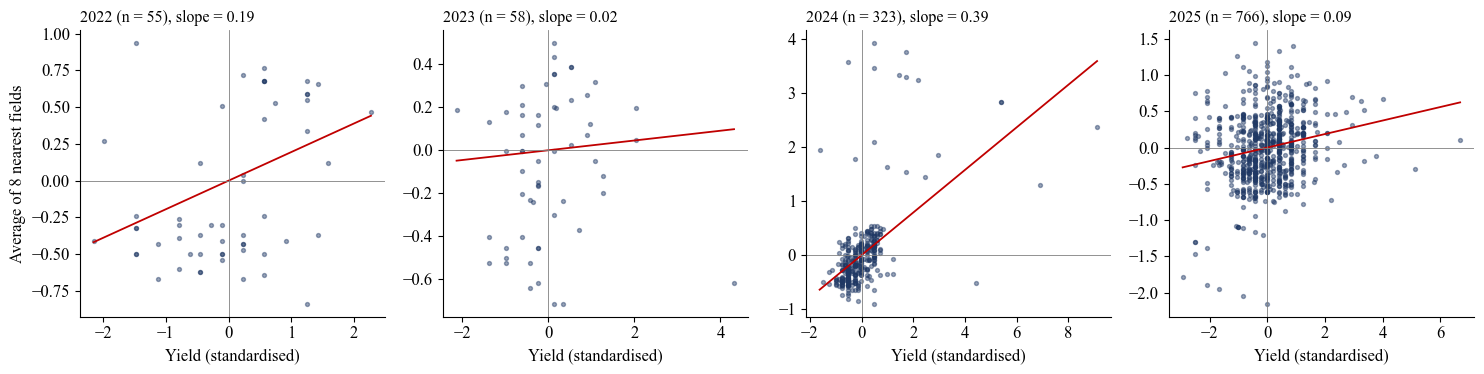

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, yr in zip(axes, YEARS):
    g = f[f["year"] == yr]
    w, keep = make_w(g[["x", "y"]].to_numpy(), "knn8")
    z = (g["crop_yield"].to_numpy() - g["crop_yield"].mean()) / g["crop_yield"].std()
    lag = np.array([np.dot(w.weights[i], z[w.neighbors[i]]) for i in range(len(z))])   # neighbours' average
    slope = np.polyfit(z, lag, 1)[0]
    ax.scatter(z, lag, s=8, color="#1F3864", alpha=0.45)
    xs = np.linspace(z.min(), z.max(), 10); ax.plot(xs, slope * xs, color="#C00000", lw=1.3)
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
    ax.set_title(f"{yr} (n = {len(z)}), slope = {slope:.2f}", loc="left", fontsize=11.5)
    ax.set_xlabel("Yield (standardised)")
axes[0].set_ylabel("Average of 8 nearest fields")
fig.tight_layout(); fig.savefig(FIG / "P2_moran_scatter.png", dpi=300, facecolor="white"); plt.show()

**Found:**
- 2024 has the steepest slope (0.39). 2025 is nearly flat (0.09), and 2023 is flat (0.02).
- Most fields sit near the middle, and the slope comes from a minority of fields in the top-right and bottom-left corners. Step 6 shows where they are.

## Step 5: Correlogram

Moran's I for rings of distance (0 to 250 m, 250 to 500 m, ... up to 10 km). Each ring compares a field only with fields at that distance. A ring is used only if it has at least 30 pairs. The distance where Moran's I falls to about zero is how far the similarity reaches.

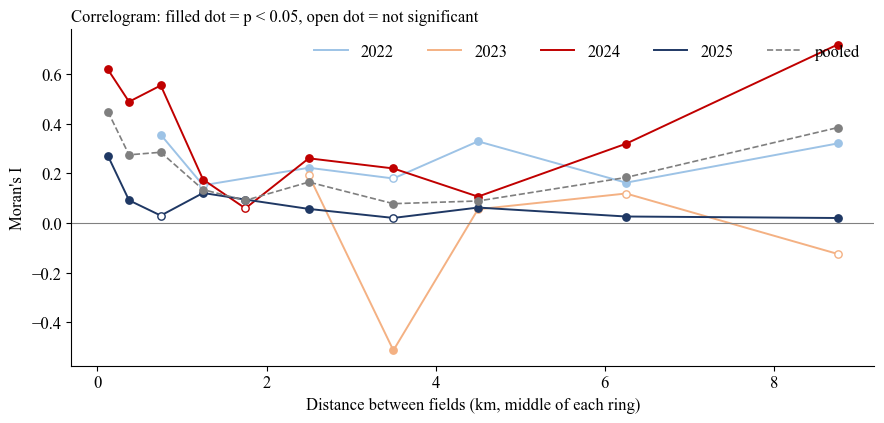

year             2022      2023     2024     2025   pooled
from_m to_m                                               
0      250        NaN       NaN  0.618 *  0.271 *  0.449 *
250    500        NaN       NaN  0.489 *  0.092 *  0.275 *
500    1000   0.356 *       NaN  0.554 *     0.03  0.285 *
1000   1500     0.152       NaN  0.175 *  0.121 *  0.135 *
1500   2000       NaN       NaN    0.059  0.095 *  0.091 *
2000   3000   0.223 *     0.192  0.261 *  0.057 *  0.165 *
3000   4000      0.18  -0.512 *   0.22 *    0.021  0.078 *
4000   5000   0.329 *     0.056  0.107 *  0.063 *  0.089 *
5000   7500   0.163 *     0.119  0.319 *  0.027 *  0.184 *
7500   10000  0.321 *    -0.124  0.718 *  0.021 *  0.384 *

first ring that is not significant: {'2022': '1 to 1.5 km', '2023': '2 to 3 km', '2024': '1.5 to 2 km', '2025': '0.5 to 1 km', 'pooled': 'beyond 10 km'}


In [5]:
BINS = [(0, 250), (250, 500), (500, 1000), (1000, 1500), (1500, 2000), (2000, 3000),
        (3000, 4000), (4000, 5000), (5000, 7500), (7500, 10000)]

def ring_w(xy, lo, hi):
    """Binary weights: neighbours are fields at a distance between lo and hi."""
    t = cKDTree(xy)
    outer, inner = t.query_ball_point(xy, hi), t.query_ball_point(xy, lo)
    neigh = {i: sorted(set(outer[i]) - set(inner[i]) - {i}) for i in range(len(xy))}
    keep = np.array([i for i in neigh if neigh[i]])
    pos = {k: n for n, k in enumerate(keep)}
    w = W({pos[i]: [pos[j] for j in neigh[i] if j in pos] for i in keep}, silence_warnings=True)
    return w, keep

rows = []
for yr in YEARS + ["pooled"]:
    for lo, hi in BINS:
        if yr == "pooled":
            parts = []
            for y_ in YEARS:                                     # rings built inside each year, then joined
                idx = np.where(f["year"].values == y_)[0]; w_, k_ = ring_w(f.loc[idx, ["x", "y"]].to_numpy(), lo, hi)
                parts.append((idx, w_, k_))
            neigh, keep_all, off = {}, [], 0
            for idx, w_, k_ in parts:
                for a, nb in w_.neighbors.items():
                    neigh[a + off] = [b + off for b in nb]
                keep_all += list(idx[k_]); off += len(k_)
            if not neigh: continue
            w = W(neigh, silence_warnings=True); y = f["yield_c"].to_numpy()[keep_all]
        else:
            idx = np.where(f["year"].values == yr)[0]
            w, keep = ring_w(f.loc[idx, ["x", "y"]].to_numpy(), lo, hi)
            y = f.loc[idx, "crop_yield"].to_numpy()[keep] if len(keep) else []
        if len(y) < 10 or w.s0 / 2 < 30: continue                 # need at least 30 pairs in the ring
        pairs = w.s0 / 2; w.transform = "r"; np.random.seed(SEED); mi = Moran(y, w, permutations=PERM)
        rows.append({"year": yr, "from_m": lo, "to_m": hi, "fields": len(y), "pairs": int(pairs),
                     "moran_I": mi.I, "p": mi.p_sim})
corr = pd.DataFrame(rows)
corr.to_csv(OUT / "P2_correlogram.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.4))
cols = {2022: "#9DC3E6", 2023: "#F4B183", 2024: "#C00000", 2025: "#1F3864", "pooled": "#7F7F7F"}
for yr, g in corr.groupby("year", sort=False):
    mid = (g["from_m"] + g["to_m"]) / 2000
    ax.plot(mid, g["moran_I"], color=cols[yr], lw=1.4 if yr != "pooled" else 1.2, ls="-" if yr != "pooled" else "--", label=str(yr))
    sig = g["p"] < 0.05
    ax.scatter(mid[sig], g.loc[sig, "moran_I"], color=cols[yr], s=28, zorder=3)
    ax.scatter(mid[~sig], g.loc[~sig, "moran_I"], facecolor="white", edgecolor=cols[yr], s=28, zorder=3)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Distance between fields (km, middle of each ring)"); ax.set_ylabel("Moran's I")
ax.set_title("Correlogram: filled dot = p < 0.05, open dot = not significant", loc="left", fontsize=12)
ax.legend(frameon=False, ncol=5, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "P2_correlogram.png", dpi=300, facecolor="white"); plt.show()

def reach(g):
    """First ring where Moran's I is not significant and positive."""
    g = g.sort_values("from_m")
    for _, r in g.iterrows():
        if not (r["p"] < 0.05 and r["moran_I"] > 0):
            return f"{r['from_m']/1000:g} to {r['to_m']/1000:g} km"
    return "beyond 10 km"
print(corr.assign(I=lambda t: t["moran_I"].round(3).astype(str) + np.where(t["p"] < 0.05, " *", "")).pivot(index=["from_m", "to_m"], columns="year", values="I").to_string())
print("\nfirst ring that is not significant:", {str(yr): reach(g) for yr, g in corr.groupby("year", sort=False)})

**Found:**
- **Very close fields are the most alike:** 0 to 250 m, Moran's I = 0.62 (2024), 0.27 (2025), 0.45 (pooled).
- **2025:** the similarity drops fast. It is 0.09 at 250 to 500 m and not significant at 500 m to 1 km. After that it stays small (0.02 to 0.12). So in 2025 the yield pattern reaches about **500 m**, plus a weak district-wide trend.
- **2024:** high up to 1 km, lower at 1.5 to 2 km, then **rising again** to 0.72 at 7.5 to 10 km. That second rise is a large-scale trend: one whole area (south Ausa) has high yields and another (west Latur) has low yields (Step 6).
- 2022 and 2023 have too few close pairs for the short rings.

## Step 6: Local statistics (LISA and Gi*)

- **Local Moran's I (LISA):** for each field, is it similar to or different from its 8 nearest fields? Classes: **High-High** and **Low-Low** (clusters), **High-Low** and **Low-High** (spatial outliers: a field unlike its neighbours).
- **Getis-Ord Gi\*:** is a field in a **hot spot** (high yields around it) or a **cold spot**?

Both use 999 permutations. Testing 1,202 fields at once gives many false alarms, so a **false discovery rate** (FDR, 5%) correction is applied in each year.

The spatial outliers (High-Low, Low-High) join the Phase 1B outlier table (`P2_local_stats.csv` has both). `P2_local_stats_map.gpkg` is the layer for QGIS.

LISA classes (k = 8, 999 permutations, FDR 5%)
year             2022  2023  2024  2025  total
lisa_class                                    
High-High           0     0    15     1     16
High-Low            0     0     2     0      2
Low-High            0     0     3     1      4
Low-Low             0     0    13    16     29
not significant    55    58   290   748   1151
total              55    58   323   766   1202

Getis-Ord Gi* classes
year             2022  2023  2024  2025  total
gi_class                                      
cold spot           0     0    16    16     32
hot spot            0     0    18     2     20
not significant    55    58   289   748   1150
total              55    58   323   766   1202

LISA vs Gi* (all years)
gi_class         cold spot  hot spot  not significant
lisa_class                                           
High-High                0        16                0
High-Low                 2         0                0
Low-High                 0     

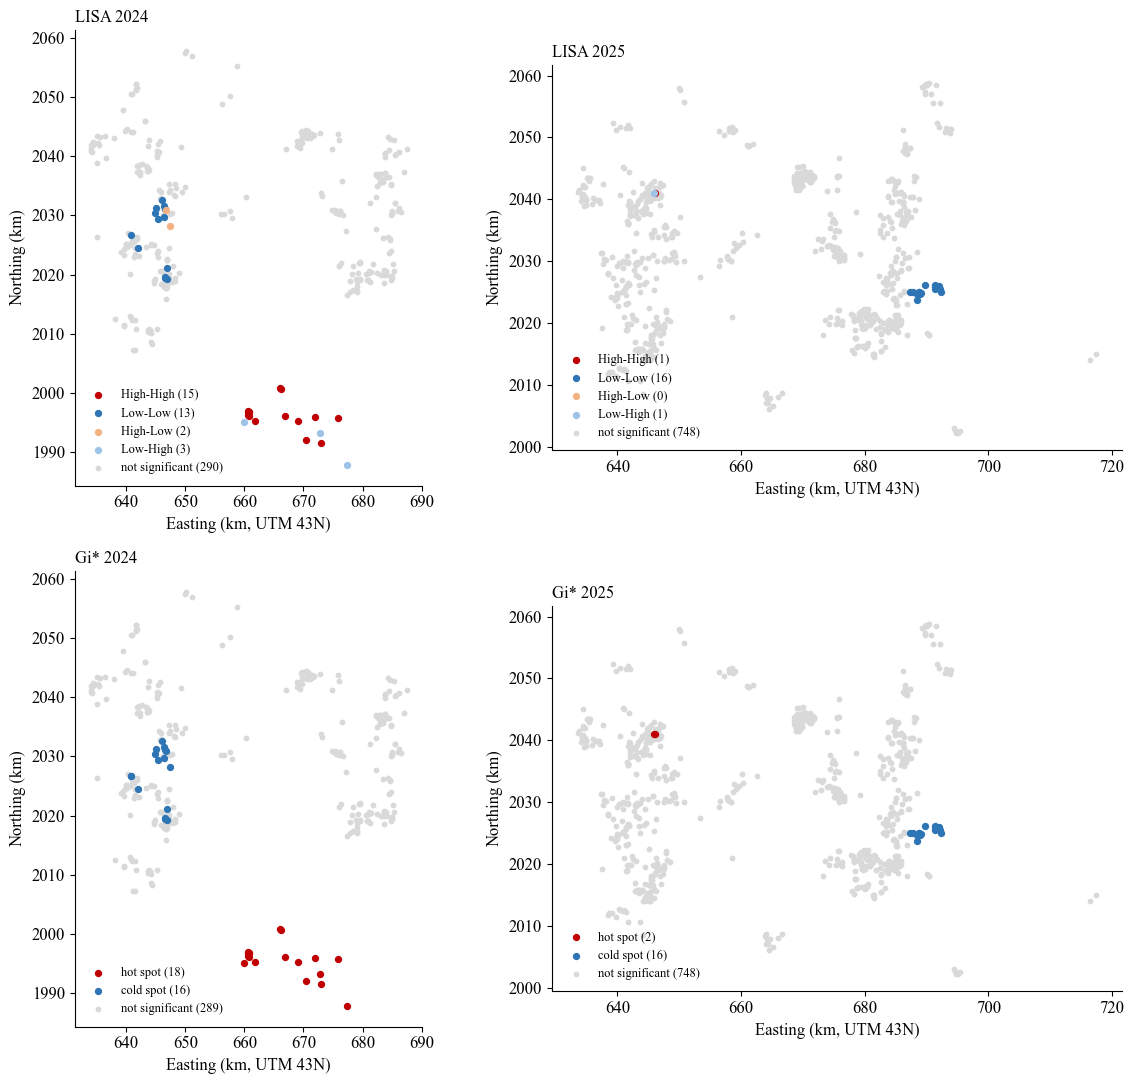

In [6]:
LISA_NAMES = {1: "High-High", 2: "Low-High", 3: "Low-Low", 4: "High-Low"}
parts = []
for yr in YEARS:
    g = f[f["year"] == yr].copy()
    xy = g[["x", "y"]].to_numpy(); y = g["crop_yield"].to_numpy()
    w, _ = make_w(xy, "knn8")
    lisa = Moran_Local(y, w, permutations=PERM, seed=SEED)
    cut = fdr(lisa.p_sim, 0.05)                           # false discovery rate cut-off for this year
    g["lisa_I"], g["lisa_p"], g["lisa_fdr_cut"] = lisa.Is, lisa.p_sim, cut
    g["lisa_class"] = np.where(lisa.p_sim <= cut, pd.Series(lisa.q).map(LISA_NAMES).values, "not significant")
    wb, _ = make_w(xy, "knn8")
    gi = G_Local(y, wb, transform="B", permutations=PERM, star=True, seed=SEED)
    cut_g = fdr(gi.p_sim, 0.05)
    g["gi_z"], g["gi_p"] = gi.Zs, gi.p_sim
    g["gi_class"] = np.where(gi.p_sim <= cut_g, np.where(gi.Zs > 0, "hot spot", "cold spot"), "not significant")
    parts.append(g)
loc = pd.concat(parts)

print("LISA classes (k = 8, 999 permutations, FDR 5%)")
print(pd.crosstab(loc["lisa_class"], loc["year"], margins=True, margins_name="total").to_string())
print("\nGetis-Ord Gi* classes")
print(pd.crosstab(loc["gi_class"], loc["year"], margins=True, margins_name="total").to_string())
print("\nLISA vs Gi* (all years)")
print(pd.crosstab(loc["lisa_class"], loc["gi_class"]).to_string())

# spatial outliers (High-Low, Low-High) join the Phase 1B outlier table
loc["spatial_outlier"] = loc["lisa_class"].isin(["High-Low", "Low-High"])
print("\nspatial outliers:", int(loc["spatial_outlier"].sum()), "| by Phase 1B group:",
      loc.loc[loc["spatial_outlier"], "yield_group"].value_counts().to_dict())
print("Phase 1B strong outliers by LISA class:", loc.loc[loc["yield_group"] == "strong", "lisa_class"].value_counts().to_dict())
print("Phase 1B strong outliers by Gi* class:", loc.loc[loc["yield_group"] == "strong", "gi_class"].value_counts().to_dict())
hot = loc[loc["gi_class"] == "hot spot"]
print("\nhot spots by taluka:", hot["taluka"].value_counts().to_dict())
print("hot-spot villages:", hot["village"].value_counts().to_dict(), "| years:", hot["year"].value_counts().to_dict())
print("cold-spot villages:", loc.loc[loc["gi_class"] == "cold spot", "village"].value_counts().to_dict())
cold = loc[loc["gi_class"] == "cold spot"]
print("cold spots by taluka:", cold["taluka"].value_counts().to_dict())

loc[["uid", "year", "village", "crop_yield", "yield_group", "lisa_I", "lisa_p", "lisa_class", "gi_z", "gi_p", "gi_class", "spatial_outlier"]] \
    .to_csv(OUT / "P2_local_stats.csv", index=False)
layer = gpd.GeoDataFrame(loc[["year", "village", "crop_yield", "yield_group", "lisa_class", "gi_class"]],
                         geometry=gpd.points_from_xy(loc["x"], loc["y"]), crs=f.crs)
layer.to_file(OUT / "P2_local_stats_map.gpkg", layer="local_stats", driver="GPKG")

# quick maps (style the gpkg in QGIS for the slides)
LC = {"High-High": "#C00000", "Low-Low": "#2E75B6", "High-Low": "#F4B183", "Low-High": "#9DC3E6", "not significant": "#D9D9D9"}
GC = {"hot spot": "#C00000", "cold spot": "#2E75B6", "not significant": "#D9D9D9"}
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for row, (col, colors) in enumerate([("lisa_class", LC), ("gi_class", GC)]):
    for ax, yr in zip(axes[row], [2024, 2025]):
        g = loc[loc["year"] == yr]
        for cls, c in colors.items():
            s = g[g[col] == cls]
            ax.scatter(s["x"] / 1000, s["y"] / 1000, s=10 if cls == "not significant" else 18, color=c, label=f"{cls} ({len(s)})", zorder=1 if cls == "not significant" else 2)
        ax.set_aspect("equal"); ax.set_title(f"{'LISA' if row == 0 else 'Gi*'} {yr}", loc="left", fontsize=12)
        ax.set_xlabel("Easting (km, UTM 43N)"); ax.set_ylabel("Northing (km)")
        ax.legend(frameon=False, fontsize=9, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "P2_lisa_gi_maps.png", dpi=300, facecolor="white"); plt.show()

**Found:**
- **2024:** 15 High-High, 13 Low-Low, 2 High-Low and 3 Low-High fields. Gi* finds 18 hot spots and 16 cold spots.
- **2025:** only 16 Low-Low fields (cold spots), 1 High-High and 1 Low-High.
- **2022, 2023:** nothing significant after the FDR correction (too few fields).
- **Hot spot:** south Ausa near Killari, in 2024 (Ganjankheda 4, Mangrul 4, Mudgad [Ekoji] 3, Killari 2, Sirsal 2). This confirms the group seen on the Phase 1B map, now with a proper test.
- **Cold spots:** in 2024 on the Latur and Ausa border, west of Latur (Chata 7, Bhada 4, Bheta 2). In 2025 in Shirur-Anantpal (Bevanal 8, Kalamgaon 7, Bevanalwadi 1), where the 16 Low-Low fields have a mean yield of 4.6 q/acre against a 2025 median of 8. Bhada is the village with many early harvests in R4.
- LISA and Gi* agree almost fully: every High-High field is a hot spot, and every Low-Low field is a cold spot.
- 11 of the 25 strong outliers from Phase 1B are High-High, meaning they sit among other high yields. The other 14 are not significant.
- **6 spatial outliers** (High-Low or Low-High). All 6 were "clean" in Phase 1B: these yields are normal for the district, but unusual for their neighbours.

## Step 7: Semivariogram (the kriging part)

The semivariogram shows how different two fields' yields are (semivariance) as the distance between them grows. Three numbers describe it:
- **Nugget:** the difference even between very close fields, meaning noise and very local effects.
- **Sill:** the difference between far-apart fields, meaning the total variation.
- **Range:** the distance where the curve flattens, meaning how far the pattern reaches.

**Nugget / sill** (Cambardella et al. 1994): below 25% = strong spatial dependence, 25 to 75% = moderate, above 75% = weak (mostly noise).

**Settings:**
- The lag width is the smallest that gives every bin at least 30 pairs. The maximum lag is half the largest distance.
- Four models are fitted: spherical, exponential, Gaussian and Matérn. The best one has the lowest leave-one-out kriging error (each field is predicted from all the others). The fit error weighted by pairs per bin is also shown.
- **Estimator:** we use **Cressie-Hawkins** (Cressie and Hawkins 1980), a robust version of the classical Matheron estimator. The yield has a long tail (Phase 1B Step 4), and the classical estimator is pulled up by a few extreme pairs. The classical estimator is shown as a check.
- **Directional variograms** (east-west, north-south and the two diagonals) check whether the pattern depends on direction. The fitted ranges per direction were unstable, so we compare the observed semivariance directly.

c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\skgstat\Kriging.py:460: KrigingWarning: For 1 locations, not enough neighbors were found within the range.
  warnings.warn('For %d locations, not enough neighbors were '
c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\skgstat\Kriging.py:460: KrigingWarning: For 1 locations, not enough neighbors were found within the range.
  warnings.warn('For %d locations, not enough neighbors were '
c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\skgstat\Kriging.py:460: KrigingWarning: For 1 locations, not enough neighbors were found within the range.
  warnings.warn('For %d locations, not enough neighbors were '
c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\skgstat\Kriging.py:460: KrigingWarning: For 1 locations, not enough neighbors were found within the range.
  warnings.warn('For %d locations, not enough neighbors were '


lag width per year (every bin has 30+ pairs): {'2022': '5000 m, 8 bins, max lag 37.4 km', '2023': '5000 m, 7 bins, max lag 30.7 km', '2024': '250 m, 151 bins, max lag 37.6 km', '2025': '250 m, 177 bins, max lag 44.1 km'}

Cressie-Hawkins, all models:
 year       model  nugget  total_sill  range_km  range_at_limit  nugget_sill_%  fit_wrmse  loo_rmse
 2022   spherical    3.56        9.40     22.99           False          37.93       2.38      2.64
 2022 exponential    2.75        9.67     29.46           False          28.40       2.59      2.63
 2022    gaussian    4.70        9.64     25.20           False          48.75       2.44      2.66
 2022      matern    4.69        9.66     25.61           False          48.60       2.45      2.66
 2023   spherical    4.01        4.76     28.24           False          84.32       0.52      2.72
 2023 exponential    3.86        4.77     30.71            True          80.79       0.51      2.72
 2023    gaussian    4.07        4.67     20.16  

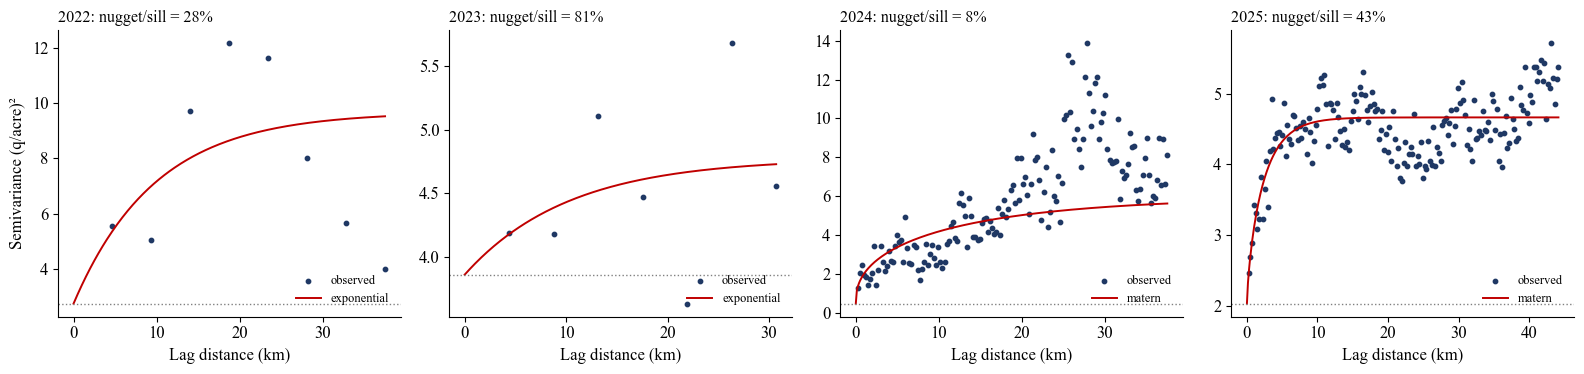


directional variograms, mean semivariance (Cressie-Hawkins):
 year   direction  pairs  semivariance_0_5km  semivariance_5_20km
 2024   east-west   7809                2.58                 4.68
 2024       NW-SE   7355                3.12                 4.16
 2024 north-south  11311                2.14                 4.29
 2024       NE-SW   6758                2.22                 3.92
 2025   east-west  70611                3.66                 4.56
 2025       NW-SE  48153                3.68                 4.53
 2025 north-south  55821                3.71                 4.79
 2025       NE-SW  44439                3.86                 4.80
2024: highest / lowest direction, 0 to 5 km = 1.46, 5 to 20 km = 1.19
2025: highest / lowest direction, 0 to 5 km = 1.05, 5 to 20 km = 1.06


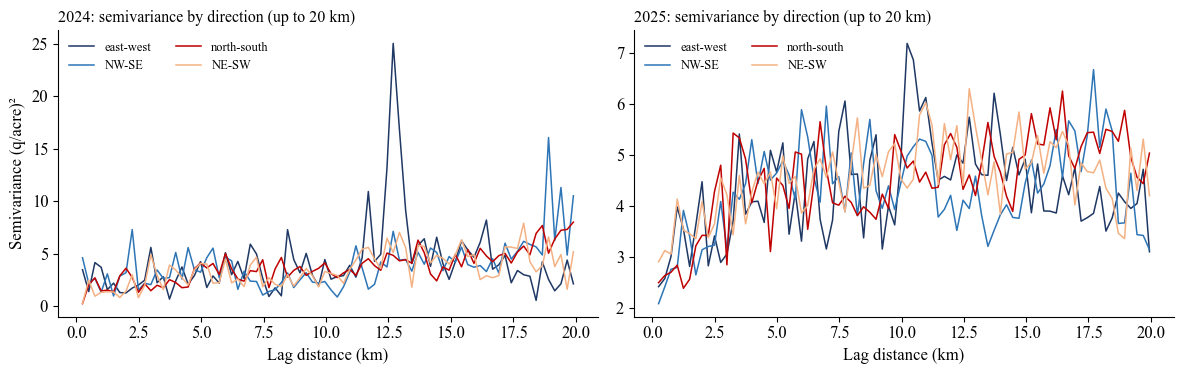

In [7]:
MODELS = ["spherical", "exponential", "gaussian", "matern"]

def pick_lag(xy, maxlag):
    """Smallest lag width (from the list) that gives every bin at least 30 pairs."""
    d = pdist(xy); d = d[d <= maxlag]
    for width in [250, 500, 1000, 2000, 3000, 5000]:
        if np.histogram(d, bins=np.arange(0, maxlag + width, width))[0].min() >= 30:
            break
    return width, int(np.ceil(maxlag / width))

def vgram(xy, y, n_lags, maxlag, model, estimator, **kw):
    return skg.Variogram(xy, y, bin_func="even", n_lags=n_lags, maxlag=maxlag, model=model, use_nugget=True,
                         estimator=estimator, fit_method="trf", fit_sigma="linear", **kw)

rows, fitted, lags = [], {}, {}
for yr in YEARS:
    g = f[f["year"] == yr]; xy = g[["x", "y"]].to_numpy(); y = g["crop_yield"].to_numpy()
    maxlag = pdist(xy).max() / 2                                     # half the largest distance
    width, n_lags = pick_lag(xy, maxlag); lags[yr] = (width, n_lags, maxlag)
    for est in ["cressie", "matheron"]:
        for m in MODELS:
            V = vgram(xy, y, n_lags, maxlag, m, est)
            exp, mod, cnt = V.experimental, V.fitted_model(V.bins), V.bin_count
            k_ = ~np.isnan(exp)
            wrmse = np.sqrt(np.sum(cnt[k_] * (exp[k_] - mod[k_]) ** 2) / cnt[k_].sum())   # fit error, weighted by pairs
            loo = V.cross_validate(method="jacknife", metric="rmse", seed=SEED) if est == "cressie" else np.nan
            d = V.describe(); nug, ps = d["nugget"], d["sill"]
            rows.append({"year": yr, "estimator": est, "model": m, "lag_m": width, "bins": n_lags, "max_lag_km": maxlag / 1000,
                         "nugget": nug, "partial_sill": ps, "total_sill": nug + ps, "range_km": d["effective_range"] / 1000,
                         "range_at_limit": d["effective_range"] >= 0.99 * maxlag,
                         "nugget_sill_%": 100 * nug / (nug + ps), "fit_wrmse": wrmse, "loo_rmse": loo})
            fitted[(yr, est, m)] = V
vario = pd.DataFrame(rows)
vario.to_csv(OUT / "P2_variogram_models.csv", index=False)
best = vario[vario["estimator"] == "cressie"].dropna(subset=["loo_rmse"])
best = best.loc[best.groupby("year")["loo_rmse"].idxmin()].copy()
best["strength"] = pd.cut(best["nugget_sill_%"], [-1, 25, 75, 101], labels=["strong", "moderate", "weak"])
best.to_csv(OUT / "P2_variogram_best.csv", index=False)
print("lag width per year (every bin has 30+ pairs):", {str(k): f"{v[0]} m, {v[1]} bins, max lag {v[2]/1000:.1f} km" for k, v in lags.items()})
print("\nCressie-Hawkins, all models:")
print(vario[vario["estimator"] == "cressie"][["year", "model", "nugget", "total_sill", "range_km", "range_at_limit", "nugget_sill_%", "fit_wrmse", "loo_rmse"]].round(2).to_string(index=False))
print("\nbest model per year (lowest leave-one-out error):")
print(best[["year", "model", "nugget", "total_sill", "range_km", "range_at_limit", "nugget_sill_%", "strength", "loo_rmse"]].round(2).to_string(index=False))
chk = vario[vario["estimator"] == "matheron"].merge(best[["year", "model"]], on=["year", "model"])
print("\ncheck with the classical Matheron estimator, same model:")
print(chk[["year", "model", "nugget", "total_sill", "range_km", "nugget_sill_%"]].round(2).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, (_, r) in zip(axes, best.iterrows()):
    V = fitted[(r["year"], "cressie", r["model"])]
    ax.scatter(V.bins / 1000, V.experimental, s=10, color="#1F3864", label="observed")
    hs = np.linspace(0, V.bins.max(), 300); ax.plot(hs / 1000, V.fitted_model(hs), color="#C00000", lw=1.4, label=r["model"])
    ax.axhline(r["nugget"], color="grey", ls=":", lw=1)
    ax.set_title(f"{r['year']}: nugget/sill = {r['nugget_sill_%']:.0f}%", loc="left", fontsize=11.5)
    ax.set_xlabel("Lag distance (km)"); ax.legend(frameon=False, fontsize=9, loc="lower right")
axes[0].set_ylabel("Semivariance (q/acre)²")
fig.tight_layout(); fig.savefig(FIG / "P2_variograms.png", dpi=300, facecolor="white"); plt.show()

# directional variograms: does the pattern depend on direction? (years with enough fields)
# skgstat measures the azimuth from east: 0 = east-west, 90 = north-south. Tolerance 45 degrees = 22.5 each side,
# so the four directions together cover every pair once. Fitted ranges per direction were unstable,
# so we compare the observed semivariance directly (no model).
DIRS = {0: "east-west", 45: "NW-SE", 90: "north-south", 135: "NE-SW"}
rows, dcurves = [], {}
for yr in [2024, 2025]:
    g = f[f["year"] == yr]; xy = g[["x", "y"]].to_numpy(); y = g["crop_yield"].to_numpy()
    width, n_lags, maxlag = lags[yr]
    for az, name in DIRS.items():
        D = skg.DirectionalVariogram(xy, y, azimuth=az, tolerance=45, bin_func="even", n_lags=n_lags, maxlag=maxlag,
                                     model="spherical", use_nugget=True, estimator="cressie")
        b, e = D.bins, D.experimental; dcurves[(yr, name)] = (b, e)
        rows.append({"year": yr, "direction": name, "pairs": int(np.nansum(D.bin_count)),
                     "semivariance_0_5km": np.nanmean(e[b <= 5000]), "semivariance_5_20km": np.nanmean(e[(b > 5000) & (b <= 20000)])})
direc = pd.DataFrame(rows)
direc.to_csv(OUT / "P2_directional_variograms.csv", index=False)
print("\ndirectional variograms, mean semivariance (Cressie-Hawkins):")
print(direc.round(2).to_string(index=False))
for yr, g in direc.groupby("year"):
    print(f"{yr}: highest / lowest direction, 0 to 5 km = {g['semivariance_0_5km'].max() / g['semivariance_0_5km'].min():.2f}, "
          f"5 to 20 km = {g['semivariance_5_20km'].max() / g['semivariance_5_20km'].min():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
DC = {"east-west": "#1F3864", "NW-SE": "#2E75B6", "north-south": "#C00000", "NE-SW": "#F4B183"}
for ax, yr in zip(axes, [2024, 2025]):
    for name in DIRS.values():
        b, e = dcurves[(yr, name)]; k_ = b <= 20000
        ax.plot(b[k_] / 1000, e[k_], color=DC[name], lw=1.1, label=name)
    ax.set_title(f"{yr}: semivariance by direction (up to 20 km)", loc="left", fontsize=11.5)
    ax.set_xlabel("Lag distance (km)"); ax.legend(frameon=False, fontsize=9, ncol=2)
axes[0].set_ylabel("Semivariance (q/acre)²")
fig.tight_layout(); fig.savefig(FIG / "P2_directional_variograms.png", dpi=300, facecolor="white"); plt.show()

**Found:**
- **2025 (best data):** Matérn, nugget/sill **43%** (moderate), range **about 7 km**. The curve rises quickly in the first 2 km and then flattens. All four models agree (43 to 57%).
- **2024:** nugget/sill **8%** (strong), but the curve keeps rising beyond 25 km and the range hits the limit (37.6 km). This is the large-scale trend from Step 5 (high south Ausa, low west Latur). So read the 8% with care: the pattern is strong, but it is partly a district-wide trend, not only a local one.
- **2022:** 28% (moderate) and **2023:** 81% (weak). Both have only 7 to 8 bins, so they are not reliable.
- **Classical estimator check:** 2025 gives 72% (moderate, near weak). In 2024 it fails (100% nugget), because the few extreme yields dominate. This is why we use Cressie-Hawkins.
- **Direction:** in 2025 the semivariance is almost the same in all directions (highest / lowest = 1.05 up to 5 km). In 2024 it differs a little (1.46 up to 5 km, lowest north-south). So there is no strong direction effect.

## Step 8: Zones (clustering)

Three ways to group fields by location (all years together, because zones are places):
- **DBSCAN** (eps 250 m to 3 km, at least 5 fields): finds dense groups of any shape. Fields far from any group become "noise".
- **HDBSCAN** (minimum zone size 5 to 30): like DBSCAN, but it chooses the distance itself.
- **K-means** (k = 2 to 20): splits the fields into k zones of similar size.

The silhouette score (Rousseeuw 1987) measures how clearly the zones are separated (higher = clearer), and the elbow plot shows where adding zones stops helping. Noise fields are left out of the silhouette, so we only accept settings that leave **at most 20% of fields as noise**. The zone IDs are saved for Phases 5 and 6, where nearby fields must not be split between training and testing.

c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
c:\Users\Predator\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10.

 method     setting  clusters  noise_%  silhouette
 DBSCAN   eps 250 m        19   89.101       0.759
 DBSCAN   eps 500 m        59   49.085       0.675
 DBSCAN  eps 1000 m        41   14.725       0.444
 DBSCAN  eps 1500 m        25    6.656       0.344
 DBSCAN  eps 2000 m        19    4.659       0.373
 DBSCAN  eps 3000 m        14    2.413       0.275
HDBSCAN  min size 5        65   18.303       0.592
HDBSCAN min size 10        22   19.551       0.617
HDBSCAN min size 20        11   30.616       0.668
HDBSCAN min size 30        10   32.113       0.680
K-means         k 2         2    0.000       0.564
K-means         k 3         3    0.000       0.518
K-means         k 4         4    0.000       0.472
K-means         k 5         5    0.000       0.482
K-means         k 6         6    0.000       0.504
K-means         k 7         7    0.000       0.478
K-means         k 8         8    0.000       0.467
K-means         k 9         9    0.000       0.472
K-means        k 10        10  

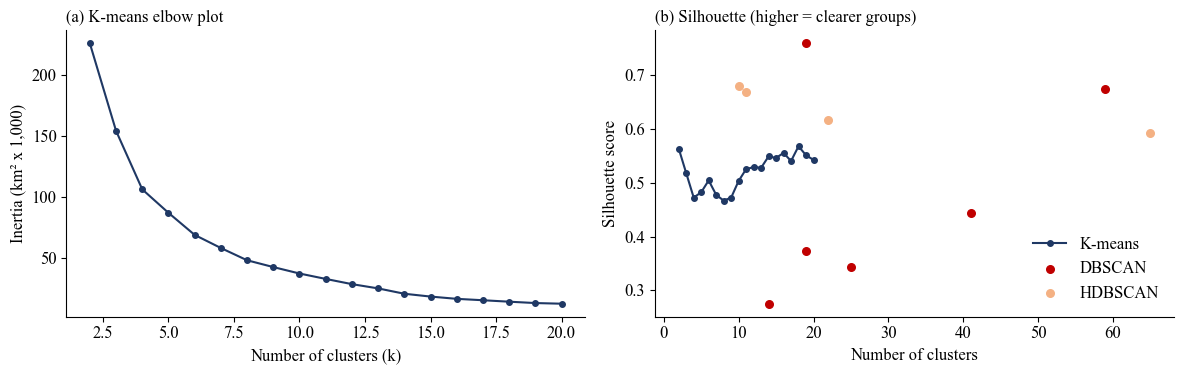


best setting per method (at most 20% noise):
 method     setting  clusters  noise_%  silhouette
HDBSCAN min size 10        22   19.551       0.617
K-means        k 18        18    0.000       0.568
 DBSCAN  eps 1000 m        41   14.725       0.444

zone columns saved: ['zone_hdbscan', 'zone_kmeans', 'zone_dbscan'] | -1 = noise (field not in any zone)


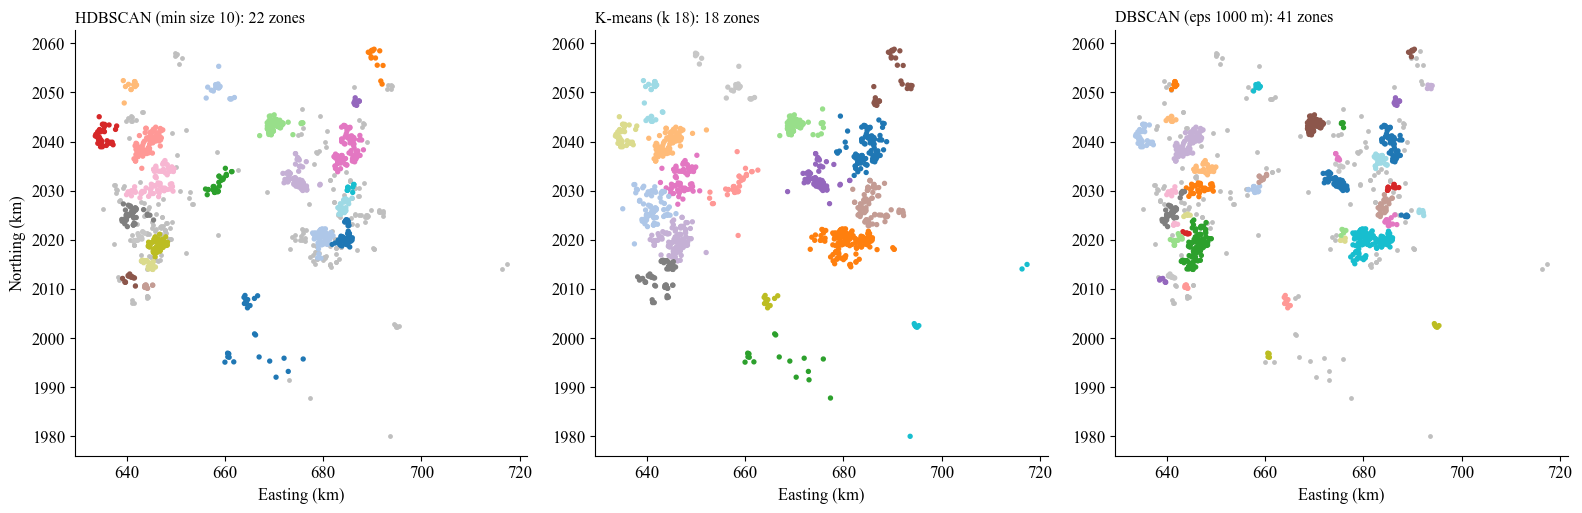

In [8]:
xy_all = f[["x", "y"]].to_numpy()          # all years together: zones are places, not years
rows, labels = [], {}
for eps in [250, 500, 1000, 1500, 2000, 3000]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(xy_all); labels[("DBSCAN", eps)] = lab
    k_ = lab >= 0; nc = len(set(lab[k_]))
    rows.append({"method": "DBSCAN", "setting": f"eps {eps} m", "clusters": nc, "noise_%": 100 * (~k_).mean(),
                 "silhouette": silhouette_score(xy_all[k_], lab[k_]) if nc > 1 else np.nan})
for mcs in [5, 10, 20, 30]:
    lab = HDBSCAN(min_cluster_size=mcs).fit_predict(xy_all); labels[("HDBSCAN", mcs)] = lab
    k_ = lab >= 0; nc = len(set(lab[k_]))
    rows.append({"method": "HDBSCAN", "setting": f"min size {mcs}", "clusters": nc, "noise_%": 100 * (~k_).mean(),
                 "silhouette": silhouette_score(xy_all[k_], lab[k_]) if nc > 1 else np.nan})
inertia = {}
for k in range(2, 21):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(xy_all); labels[("K-means", k)] = km.labels_; inertia[k] = km.inertia_
    rows.append({"method": "K-means", "setting": f"k {k}", "clusters": k, "noise_%": 0.0, "silhouette": silhouette_score(xy_all, km.labels_)})
clus = pd.DataFrame(rows)
clus.to_csv(OUT / "P2_clustering_scores.csv", index=False)
print(clus.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ks = list(inertia); axes[0].plot(ks, np.array(list(inertia.values())) / 1e9, marker="o", color="#1F3864", ms=4)
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("Inertia (km² x 1,000)"); axes[0].set_title("(a) K-means elbow plot", loc="left", fontsize=12)
km_s = clus[clus["method"] == "K-means"]
axes[1].plot(km_s["clusters"], km_s["silhouette"], marker="o", color="#1F3864", ms=4, label="K-means")
for mth, c in [("DBSCAN", "#C00000"), ("HDBSCAN", "#F4B183")]:
    s = clus[clus["method"] == mth]; axes[1].scatter(s["clusters"], s["silhouette"], color=c, s=30, label=mth, zorder=3)
axes[1].set_xlabel("Number of clusters"); axes[1].set_ylabel("Silhouette score"); axes[1].legend(frameon=False)
axes[1].set_title("(b) Silhouette (higher = clearer groups)", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "P2_clustering_scores.png", dpi=300, facecolor="white"); plt.show()

# choose: settings that leave at most 20% of fields without a zone, then the highest silhouette per method
ok_c = clus[clus["noise_%"] <= 20]
chosen = ok_c.loc[ok_c.groupby("method")["silhouette"].idxmax()].sort_values("silhouette", ascending=False)
print("\nbest setting per method (at most 20% noise):")
print(chosen.round(3).to_string(index=False))
key = {"DBSCAN": lambda s: int(s.split()[1]), "HDBSCAN": lambda s: int(s.split()[2]), "K-means": lambda s: int(s.split()[1])}
for _, r in chosen.iterrows():
    f[f"zone_{r['method'].lower().replace('-', '')}"] = labels[(r["method"], key[r["method"]](r["setting"]))]
zcols = [c for c in f.columns if c.startswith("zone_")]
f[["uid", "year", *zcols]].to_csv(OUT / "P2_zones.csv", index=False)
print("\nzone columns saved:", zcols, "| -1 = noise (field not in any zone)")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, (_, r) in zip(axes, chosen.iterrows()):
    col = f"zone_{r['method'].lower().replace('-', '')}"; lab = f[col].to_numpy()
    ax.scatter(f.loc[lab < 0, "x"] / 1000, f.loc[lab < 0, "y"] / 1000, s=6, color="#BFBFBF", label="noise")
    ax.scatter(f.loc[lab >= 0, "x"] / 1000, f.loc[lab >= 0, "y"] / 1000, s=8, c=lab[lab >= 0] % 20, cmap="tab20")
    ax.set_aspect("equal"); ax.set_xlabel("Easting (km)")
    ax.set_title(f"{r['method']} ({r['setting']}): {int(r['clusters'])} zones", loc="left", fontsize=11.5)
axes[0].set_ylabel("Northing (km)")
fig.tight_layout(); fig.savefig(FIG / "P2_zones_map.png", dpi=300, facecolor="white"); plt.show()

**Found:**
- **HDBSCAN (minimum size 10)** has the best silhouette (0.62), with 23 zones and 19.6% noise fields.
- **K-means:** the best silhouette is at k = 18 (0.57). The elbow plot has no sharp bend.
- **DBSCAN:** with at most 20% noise, the best is eps 1 km (41 zones, 14.7% noise, silhouette 0.44).
- Settings with a high silhouette but a lot of noise (DBSCAN 250 m: 89% noise) were not accepted.
- All three zone columns are saved. The final choice is made in Phase 5, together with the grouping distance (decision log row 13).

## Step 9: Decision rule

| Finding | Meaning | Next step |
|---|---|---|
| Moran's I significant, nugget/sill below 75% | real spatial pattern | spatial features and regression kriging in Phase 7 are worth it |
| Moran's I near 0, nugget/sill above 75% | mostly noise or very local effects | spatial priors will help little; strong evidence for label noise |
| Pattern in SAR but not in yield | labels do not follow the crop signal | supports the label-noise argument (checked after Phase 3) |

Moran's I uses k = 8 neighbours; nugget/sill comes from the best Cressie-Hawkins model.

In [9]:
rows = []
for yr in YEARS:
    gm = glob[(glob["year"] == yr) & (glob["weights"] == "knn8")].iloc[0]
    b = best[best["year"] == yr].iloc[0]
    sig, ns = gm["moran_p"] < 0.05, b["nugget_sill_%"]
    if sig and ns < 75:
        meaning, step = "real spatial pattern", "spatial features and regression kriging (Phase 7) are worth testing"
    elif (not sig) and ns >= 75:
        meaning, step = "mostly noise or very local effects", "spatial priors will help little; supports label noise"
    else:
        meaning, step = "mixed evidence", "test spatial features, but expect a small gain"
    rows.append({"year": yr, "fields": int(gm["n"]), "moran_I_knn8": round(gm["moran_I"], 3), "moran_p": gm["moran_p"],
                 "nugget_sill_%": round(ns, 0), "meaning": meaning, "next_step": step})
decision = pd.DataFrame(rows)
decision.to_csv(OUT / "P2_decision.csv", index=False)
print(decision.to_string(index=False))

# save the spatial results with each field for later phases
keep_cols = ["uid", "lisa_class", "gi_class", "spatial_outlier"]
out = f.merge(loc[keep_cols], on="uid", how="left")
gpd.GeoDataFrame(out.drop(columns=["x", "y"]), geometry="geometry", crs=f.crs).to_file(DATA2 / "yield_spatial_v2.gpkg", driver="GPKG")
print("\nsaved:", DATA2 / "yield_spatial_v2.gpkg", "|", len(out), "fields")

 year  fields  moran_I_knn8  moran_p  nugget_sill_%                            meaning                                                           next_step
 2022      55         0.194    0.004           28.0               real spatial pattern spatial features and regression kriging (Phase 7) are worth testing
 2023      58         0.023    0.203           81.0 mostly noise or very local effects               spatial priors will help little; supports label noise
 2024     323         0.395    0.001            8.0               real spatial pattern spatial features and regression kriging (Phase 7) are worth testing
 2025     766         0.093    0.001           43.0               real spatial pattern spatial features and regression kriging (Phase 7) are worth testing

saved: f:\THESIS\mtech_thesis_crop_yield_estimation\data\processed_v2\yield_spatial_v2.gpkg | 1202 fields


**Found:**
- **2022, 2024 and 2025:** real spatial pattern. Spatial features and regression kriging are worth testing in Phase 7.
- **2023:** no clear pattern (Moran's I 0.02, nugget/sill 81%), but it has only 58 fields.
- Even where there is a pattern, the nugget is large in 2025 (43%). So a big part of the yield differences between close fields is noise or very local effects. This supports the label-noise argument from Phase 1B (rounding of ±0.5 q/acre).

## Summary

| Question | Answer |
|---|---|
| Do nearby fields have similar yields? | yes in 2022, 2024, 2025 and pooled; strong in 2024 (I = 0.40), weak in 2025 (0.09), none in 2023 |
| Caused by outliers? | no: same result without strong outliers and on ranks |
| How far? | about 500 m in 2025; 2024 also has a district-wide trend |
| Hot spots | south Ausa near Killari (2024) |
| Cold spots | west of Latur: Chata, Bhada, Bheta (2024); Shirur-Anantpal: Bevanal, Kalamgaon (2025) |
| Spatial outliers | 6 fields, all "clean" in Phase 1B |
| Nugget / sill | 2025: 43% (moderate), 2024: 8% (strong, but trend), 2023: 81% (weak) |
| Direction effect | none in 2025, small in 2024 |
| Zones | HDBSCAN 23 zones (best), K-means 18, DBSCAN 41 |
| Decision | spatial pattern is real; test spatial features and regression kriging in Phase 7 |

**Limits**
- 2022 and 2023 have too few fields for local statistics and reliable variograms.
- The 2024 variogram does not level off within half the district, because of the large-scale trend.
- The SAR variogram (2.6.6) and the K-means on SAR curves (2.7) wait for Phase 3.

**References**
- Anselin, L. (1995). Local indicators of spatial association: LISA. Geographical Analysis, 27(2), 93-115.
- Benjamini, Y. and Hochberg, Y. (1995). Controlling the false discovery rate. Journal of the Royal Statistical Society B, 57(1), 289-300.
- Cambardella, C.A. et al. (1994). Field-scale variability of soil properties in central Iowa soils. Soil Science Society of America Journal, 58(5), 1501-1511.
- Campello, R.J.G.B., Moulavi, D. and Sander, J. (2013). Density-based clustering based on hierarchical density estimates. PAKDD 2013, LNCS 7819, 160-172.
- Cressie, N. and Hawkins, D.M. (1980). Robust estimation of the variogram: I. Mathematical Geology, 12(2), 115-125.
- Ester, M., Kriegel, H.-P., Sander, J. and Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. KDD-96, 226-231.
- Geary, R.C. (1954). The contiguity ratio and statistical mapping. The Incorporated Statistician, 5(3), 115-145.
- Getis, A. and Ord, J.K. (1992). The analysis of spatial association by use of distance statistics. Geographical Analysis, 24(3), 189-206.
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. Proceedings of the 5th Berkeley Symposium, 1, 281-297.
- Matheron, G. (1963). Principles of geostatistics. Economic Geology, 58(8), 1246-1266.
- Moran, P.A.P. (1950). Notes on continuous stochastic phenomena. Biometrika, 37(1/2), 17-23.
- Ord, J.K. and Getis, A. (1995). Local spatial autocorrelation statistics: distributional issues and an application. Geographical Analysis, 27(4), 286-306.
- Rousseeuw, P.J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. Journal of Computational and Applied Mathematics, 20, 53-65.